
MODEL: Multinomial NB (Baseline)
              precision    recall  f1-score   support

          ai       1.00      0.19      0.32        47
   classical       0.82      1.00      0.90       178

    accuracy                           0.83       225
   macro avg       0.91      0.60      0.61       225
weighted avg       0.86      0.83      0.78       225


MODEL: Logistic Regression
              precision    recall  f1-score   support

          ai       0.77      0.79      0.78        47
   classical       0.94      0.94      0.94       178

    accuracy                           0.91       225
   macro avg       0.86      0.86      0.86       225
weighted avg       0.91      0.91      0.91       225


MODEL: Linear SVM
              precision    recall  f1-score   support

          ai       0.95      0.74      0.83        47
   classical       0.94      0.99      0.96       178

    accuracy                           0.94       225
   macro avg       0.94      0.87      0.90    

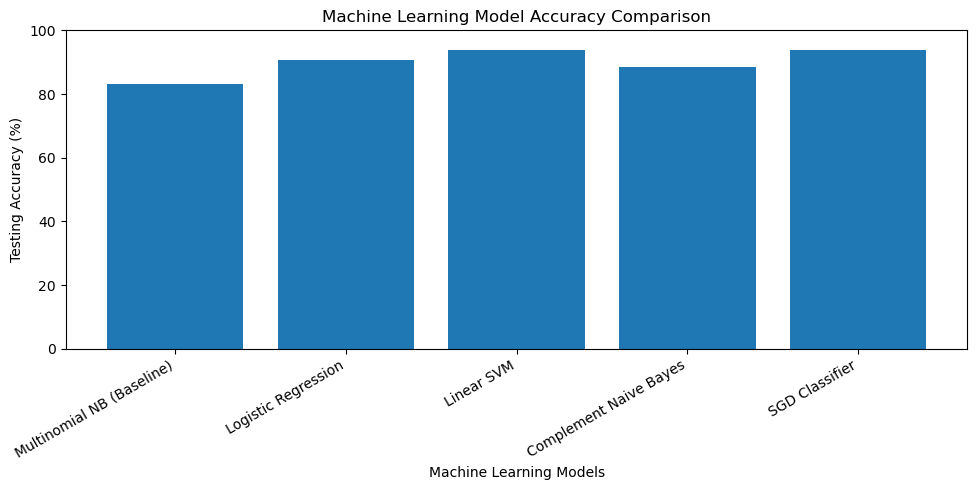

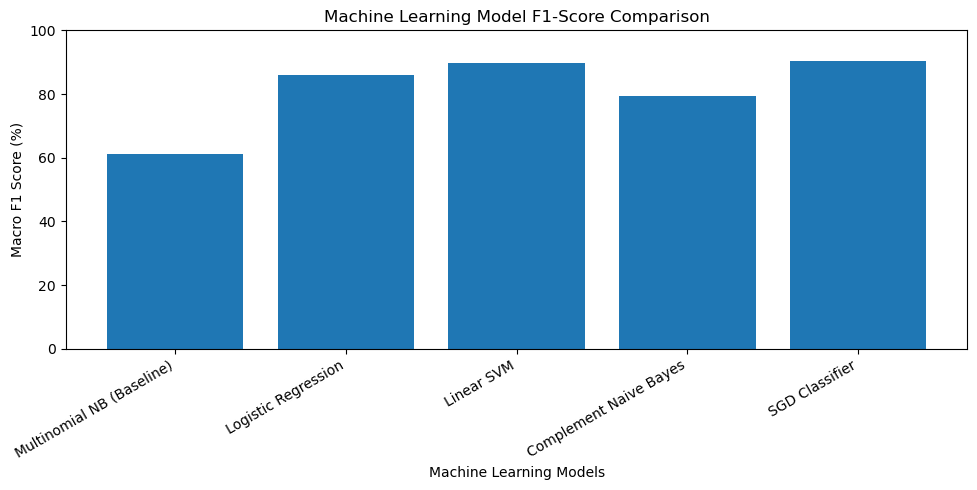


Question 2.1 Completed Successfully!


In [5]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

df = pd.read_csv('cleaned_research_abstracts.csv')


df = df.dropna(subset=['Cleaned_Abstract', 'Label'])


X = df['Cleaned_Abstract']
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


models = {
    'Multinomial NB (Baseline)': MultinomialNB(),
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),
    'Linear SVM': LinearSVC(
        class_weight='balanced',
        random_state=42
    ),
    'Complement Naive Bayes': ComplementNB(),
    'SGD Classifier': SGDClassifier(
        loss='hinge',
        class_weight='balanced',
        random_state=42
    )
}

results = []

for name, classifier in models.items():


    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ('classifier', classifier)
    ])

    pipeline.fit(X_train, y_train)


    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)


    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    precision = precision_score(
        y_test, y_test_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_test_pred,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_test_pred,
        average='macro',
        zero_division=0
    )

    results.append({
        'Model': name,
        'Training Accuracy': train_accuracy,
        'Testing Accuracy': test_accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("\nMODEL:", name)
    print(classification_report(
        y_test,
        y_test_pred,
        zero_division=0
    ))


results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))

best_model = results_df.loc[
    results_df['F1 Score'].idxmax()
]

print("\nBEST PERFORMING MODEL")
print("Model:", best_model['Model'])
print("Testing Accuracy: {:.2f}%".format(
    best_model['Testing Accuracy'] * 100
))
print("Macro F1 Score: {:.2f}%".format(
    best_model['F1 Score'] * 100
))

plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Model'],
    results_df['Testing Accuracy'] * 100
)

plt.title('Machine Learning Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Testing Accuracy (%)')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.bar(
    results_df['Model'],
    results_df['F1 Score'] * 100
)

plt.title('Machine Learning Model F1-Score Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Macro F1 Score (%)')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

results_df.to_csv('model_comparison_results.csv', index=False)

print("\nQuestion 2.1 Completed Successfully!")
